# Step 5: Hybrid 3-Stage Pipeline - YOGA Chatbot

**Chatbot Name**: YOGA (YOgyakarta Guide Assistant)

**Objective**: Combine GreetingDetector + MainClassifier for improved greeting intent detection

**Date**: 2025-12-01

**Architecture**:
- **Stage 0**: Rule-based filter (word count > 3 → skip greeting)
- **Stage 1**: Binary GreetingDetector (greeting vs non-greeting)
- **Stage 2**: Conditional MainClassifier (6 greeting OR 82 location classes)

**Expected Benefit**: Better greeting detection without reducing location performance

## 1. Import Libraries

In [58]:
import numpy as np
import pandas as pd
import json
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
np.random.seed(42)

print("Libraries imported successfully")

Libraries imported successfully


## 2. Load Models and Vectorizers

In [59]:
print("=" * 80)
print("LOADING MODELS AND VECTORIZERS")
print("=" * 80)

# Load Binary GreetingDetector
with open('../models/greeting_detector.pkl', 'rb') as f:
    greeting_detector = pickle.load(f)
print("Loaded: greeting_detector.pkl")

# Load Main SVM Classifier
with open('../models/svm_model.pkl', 'rb') as f:
    main_classifier = pickle.load(f)
print("Loaded: svm_model.pkl")

# Load TF-IDF vectorizers
with open('../data/features/tfidf_greeting.pickle', 'rb') as f:
    tfidf_greeting = pickle.load(f)
print("Loaded: tfidf_greeting.pickle")

with open('../data/features/tfidf_vectorizer.pickle', 'rb') as f:
    tfidf_main = pickle.load(f)
print("Loaded: tfidf_vectorizer.pickle")

# Load label encoder
with open('../data/features/label_encoder.pickle', 'rb') as f:
    label_encoder = pickle.load(f)
print("Loaded: label_encoder.pickle")

print(f"\nTotal classes: {len(label_encoder.classes_)}")

LOADING MODELS AND VECTORIZERS
Loaded: greeting_detector.pkl
Loaded: svm_model.pkl
Loaded: tfidf_greeting.pickle
Loaded: tfidf_vectorizer.pickle
Loaded: label_encoder.pickle

Total classes: 88


## 3. Load Test Data

In [60]:
print("=" * 80)
print("LOADING TEST DATA")
print("=" * 80)

# Load preprocessed data
df = pd.read_csv('../data/preprocessed/preprocessed_text.csv')

print(f"Total samples: {len(df)}")
print(f"Columns: {list(df.columns)}")

# Use same train-test split as SVM modeling (80-20)
from sklearn.model_selection import train_test_split

X_text = df['processed_text'].values
y = label_encoder.transform(df['label'].values)

_, X_test_text, _, y_test = train_test_split(
    X_text, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"\nTest samples: {len(X_test_text)}")
print(f"Test labels: {len(y_test)}")

LOADING TEST DATA
Total samples: 2247
Columns: ['pattern', 'processed_text', 'label']

Test samples: 450
Test labels: 450


## 4. Define Greeting Classes

In [61]:
# Define greeting intents
greeting_intents = ['goodbye', 'greeting', 'pagi', 'siang', 'sore', 'malam']
greeting_indices = [i for i, cls in enumerate(label_encoder.classes_) if cls in greeting_intents]

print("=" * 80)
print("GREETING CLASSES")
print("=" * 80)

print(f"\nGreeting intents: {greeting_intents}")
print(f"Greeting class indices: {greeting_indices}")

# Create mapping for greeting subset classifier
greeting_label_map = {idx: i for i, idx in enumerate(greeting_indices)}
greeting_class_names = [label_encoder.classes_[idx] for idx in greeting_indices]

print(f"\nGreeting class names: {greeting_class_names}")

GREETING CLASSES

Greeting intents: ['goodbye', 'greeting', 'pagi', 'siang', 'sore', 'malam']
Greeting class indices: [0, 1, 83, 84, 86, 87]

Greeting class names: ['goodbye', 'greeting', 'malam', 'pagi', 'siang', 'sore']


## 5. Hybrid Prediction Pipeline

In [62]:
def predict_hybrid(text, confidence_threshold=0.7):
    """
    3-Stage Hybrid Prediction Pipeline

    Stage 0: Rule-based filter
    - If word count > 3 → Skip to MainClassifier

    Stage 1: Binary GreetingDetector
    - Classify: greeting vs non-greeting
    - Get probability/confidence

    Stage 2: Conditional Classification
    - If GREETING (confidence >= threshold):
      → Get decision scores from MainClassifier
      → Only pick from 6 greeting classes (ignore location scores)
    - If NON-GREETING (confidence < threshold):
      → Use MainClassifier normally

    Args:
        text: Preprocessed input text
        confidence_threshold: Threshold for greeting detection (default 0.7)

    Returns:
        predicted_class_index: Integer class index
    """

    # Stage 0: Rule-based filter
    word_count = len(text.split())

    if word_count > 3:
        # Long text → likely location query → Skip to MainClassifier
        X_main = tfidf_main.transform([text]).toarray()
        pred_idx = main_classifier.predict(X_main)[0]
        return pred_idx

    # Stage 1: Binary GreetingDetector
    X_greeting = tfidf_greeting.transform([text]).toarray()
    greeting_proba = greeting_detector.predict_proba(X_greeting)[0]

    # greeting_proba[1] = probability of being a greeting
    confidence = greeting_proba[1]

    # Stage 2: Conditional Classification
    X_main = tfidf_main.transform([text]).toarray()
    
    if confidence >= confidence_threshold:
        # GREETING detected → Only pick from 6 greeting classes
        all_scores = main_classifier.decision_function(X_main)[0]
        
        # Only consider greeting classes
        greeting_scores = [(idx, all_scores[idx]) for idx in greeting_indices]
        pred_idx = max(greeting_scores, key=lambda x: x[1])[0]
        
        return pred_idx
    else:
        # NON-GREETING → Use MainClassifier normally
        pred_idx = main_classifier.predict(X_main)[0]
        return pred_idx

print("Hybrid prediction function defined")
print("\nPipeline stages:")
print("  Stage 0: Rule filter (word_count > 3 → MainClassifier)")
print("  Stage 1: GreetingDetector (binary classification)")
print("  Stage 2: Conditional classification")
print("    - GREETING (conf >= 0.7) → Pick best among 6 greeting classes")
print("    - NON-GREETING (conf < 0.7) → Use MainClassifier normally")

Hybrid prediction function defined

Pipeline stages:
  Stage 0: Rule filter (word_count > 3 → MainClassifier)
  Stage 1: GreetingDetector (binary classification)
  Stage 2: Conditional classification
    - GREETING (conf >= 0.7) → Pick best among 6 greeting classes
    - NON-GREETING (conf < 0.7) → Use MainClassifier normally


## 6. Run Hybrid Predictions

In [63]:
print("=" * 80)
print("RUNNING HYBRID PREDICTIONS")
print("=" * 80)

# Run predictions with hybrid pipeline
y_pred_hybrid = []

print(f"\nProcessing {len(X_test_text)} test samples...")

for i, text in enumerate(X_test_text):
    pred = predict_hybrid(text, confidence_threshold=0.7)
    y_pred_hybrid.append(pred)
    
    if (i + 1) % 100 == 0:
        print(f"  Processed {i + 1}/{len(X_test_text)} samples")

y_pred_hybrid = np.array(y_pred_hybrid)

print(f"\nPredictions complete: {len(y_pred_hybrid)} samples")

RUNNING HYBRID PREDICTIONS

Processing 450 test samples...
  Processed 100/450 samples
  Processed 200/450 samples
  Processed 300/450 samples
  Processed 400/450 samples

Predictions complete: 450 samples


## 7. Evaluate Hybrid Pipeline

In [64]:
print("=" * 80)
print("HYBRID PIPELINE EVALUATION")
print("=" * 80)

# Accuracy
hybrid_accuracy = accuracy_score(y_test, y_pred_hybrid)

print(f"\nHybrid Test Accuracy: {hybrid_accuracy*100:.2f}%")
print(f"\nTotal test samples: {len(y_test)}")
print(f"Correct predictions: {(y_pred_hybrid == y_test).sum()}")
print(f"Wrong predictions: {(y_pred_hybrid != y_test).sum()}")

# Classification report
from sklearn.metrics import precision_recall_fscore_support

report_hybrid = classification_report(
    y_test,
    y_pred_hybrid,
    labels=list(range(len(label_encoder.classes_))),
    target_names=label_encoder.classes_,
    digits=4,
    zero_division=0,
    output_dict=True
)

print(f"\nMacro Avg F1: {report_hybrid['macro avg']['f1-score']*100:.2f}%")
print(f"Weighted Avg F1: {report_hybrid['weighted avg']['f1-score']*100:.2f}%")

HYBRID PIPELINE EVALUATION

Hybrid Test Accuracy: 97.56%

Total test samples: 450
Correct predictions: 439
Wrong predictions: 11

Macro Avg F1: 97.71%
Weighted Avg F1: 97.73%


## 8. Compare Greeting Intent Performance

In [65]:
print("=" * 80)
print("GREETING INTENT PERFORMANCE COMPARISON")
print("=" * 80)

# Load baseline SVM predictions
# Re-run baseline SVM for comparison
X_test_main = tfidf_main.transform(X_test_text).toarray()  # Convert to dense
y_pred_baseline = main_classifier.predict(X_test_main)

# Get metrics for greeting intents
precision_hybrid, recall_hybrid, f1_hybrid, support = precision_recall_fscore_support(
    y_test, y_pred_hybrid,
    labels=greeting_indices,
    zero_division=0
)

precision_baseline, recall_baseline, f1_baseline, _ = precision_recall_fscore_support(
    y_test, y_pred_baseline,
    labels=greeting_indices,
    zero_division=0
)

# Create comparison DataFrame
comparison_df = pd.DataFrame({
    'Intent': greeting_class_names,
    'Baseline_F1': f1_baseline,
    'Hybrid_F1': f1_hybrid,
    'Improvement': f1_hybrid - f1_baseline,
    'Support': support
})

print("\nGreeting Intent F1-Score Comparison:")
print(comparison_df.to_string(index=False))

print(f"\nAverage Greeting F1:")
print(f"  Baseline: {f1_baseline.mean()*100:.2f}%")
print(f"  Hybrid: {f1_hybrid.mean()*100:.2f}%")
print(f"  Improvement: {(f1_hybrid.mean() - f1_baseline.mean())*100:.2f}%")

GREETING INTENT PERFORMANCE COMPARISON

Greeting Intent F1-Score Comparison:
  Intent  Baseline_F1  Hybrid_F1  Improvement  Support
 goodbye     0.400000   0.400000     0.000000        5
greeting     0.833333   0.833333     0.000000        5
   malam     0.888889   0.888889     0.000000        5
    pagi     0.571429   0.571429     0.000000        5
   siang     1.000000   1.000000     0.000000        5
    sore     0.750000   0.888889     0.138889        5

Average Greeting F1:
  Baseline: 74.06%
  Hybrid: 76.38%
  Improvement: 2.31%


## 9. Visualizations

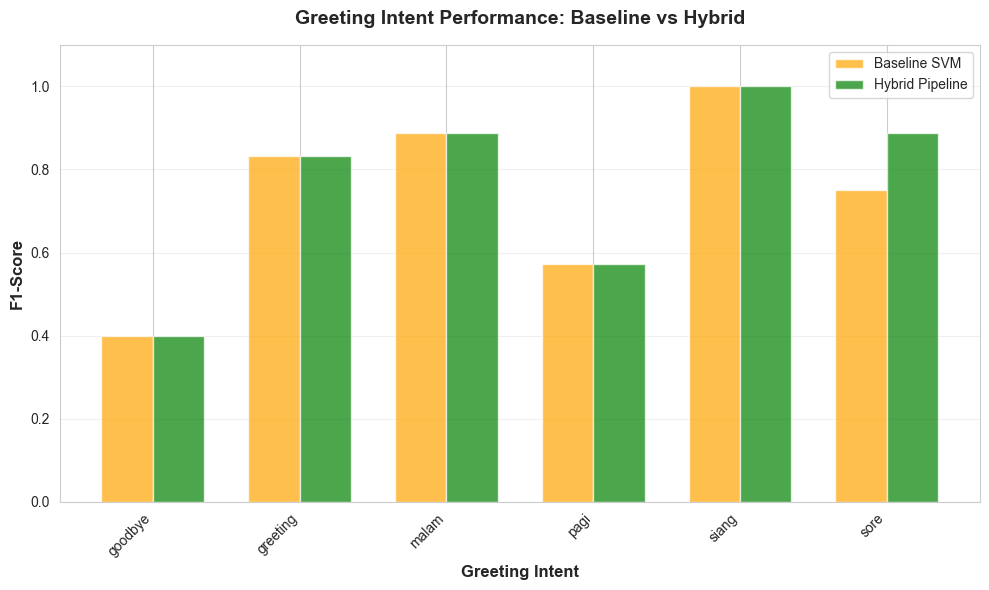

Greeting comparison saved


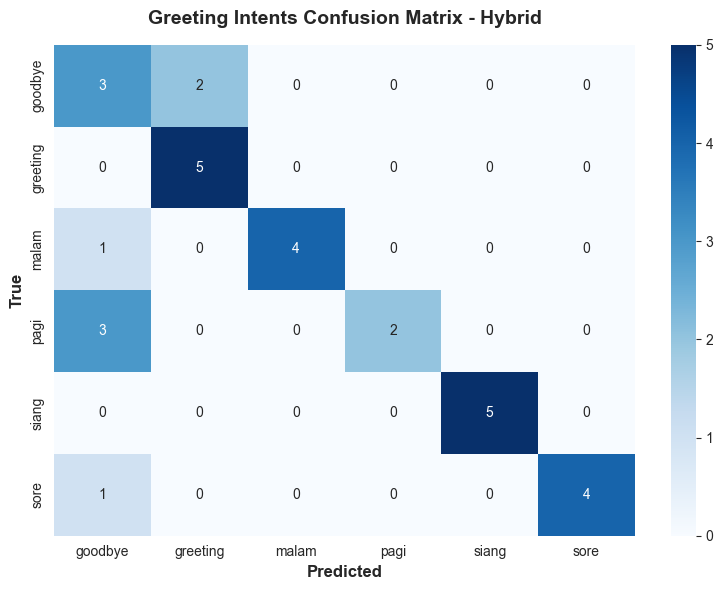

Greeting confusion matrix saved


In [66]:
# Greeting F1 comparison
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(greeting_class_names))
width = 0.35

ax.bar(x - width/2, comparison_df['Baseline_F1'], width, label='Baseline SVM', alpha=0.7, color='orange')
ax.bar(x + width/2, comparison_df['Hybrid_F1'], width, label='Hybrid Pipeline', alpha=0.7, color='green')

ax.set_xlabel('Greeting Intent', fontsize=12, fontweight='bold')
ax.set_ylabel('F1-Score', fontsize=12, fontweight='bold')
ax.set_title('Greeting Intent Performance: Baseline vs Hybrid', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(greeting_class_names, rotation=45, ha='right')
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1.1])

plt.tight_layout()
os.makedirs('../models', exist_ok=True)
plt.savefig('../models/hybrid_greeting_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("Greeting comparison saved")

# Confusion matrix for greeting intents only
y_test_greeting_mask = np.isin(y_test, greeting_indices)
y_test_greeting = y_test[y_test_greeting_mask]
y_pred_hybrid_greeting = y_pred_hybrid[y_test_greeting_mask]

# Map to 0-5 range for confusion matrix
y_test_greeting_mapped = np.array([greeting_indices.index(label) for label in y_test_greeting])
y_pred_hybrid_greeting_mapped = np.array([greeting_indices.index(label) for label in y_pred_hybrid_greeting])

cm_greeting = confusion_matrix(y_test_greeting_mapped, y_pred_hybrid_greeting_mapped)

plt.figure(figsize=(8, 6))
sns.heatmap(cm_greeting, annot=True, fmt='d', cmap='Blues',
            xticklabels=greeting_class_names,
            yticklabels=greeting_class_names)
plt.xlabel('Predicted', fontsize=12, fontweight='bold')
plt.ylabel('True', fontsize=12, fontweight='bold')
plt.title('Greeting Intents Confusion Matrix - Hybrid', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('../models/hybrid_greeting_cm.png', dpi=300, bbox_inches='tight')
plt.show()

print("Greeting confusion matrix saved")

## 10. Save Results

In [67]:
print("=" * 80)
print("SAVING RESULTS")
print("=" * 80)

# Save comparison results
comparison_df.to_csv('../models/hybrid_comparison.csv', index=False)
print("Saved: hybrid_comparison.csv")

# Save hybrid pipeline info
from datetime import datetime

hybrid_info = {
    'pipeline_name': 'Hybrid_3Stage_Pipeline',
    'stage_0': 'Rule-based filter (word_count > 3)',
    'stage_1': 'Binary GreetingDetector (SVM)',
    'stage_2': 'Conditional MainClassifier (88-class SVM)',
    'confidence_threshold': 0.7,
    'greeting_intents': greeting_intents,
    'hybrid_accuracy': float(hybrid_accuracy),
    'baseline_accuracy': float(accuracy_score(y_test, y_pred_baseline)),
    'greeting_avg_f1_baseline': float(f1_baseline.mean()),
    'greeting_avg_f1_hybrid': float(f1_hybrid.mean()),
    'greeting_f1_improvement': float(f1_hybrid.mean() - f1_baseline.mean()),
    'test_samples': len(y_test),
    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S')
}

with open('../models/hybrid_pipeline_info.json', 'w') as f:
    json.dump(hybrid_info, f, indent=2)
print("Saved: hybrid_pipeline_info.json")

print("\nAll files saved successfully")

SAVING RESULTS
Saved: hybrid_comparison.csv
Saved: hybrid_pipeline_info.json

All files saved successfully


## 11. Summary

In [68]:
print("=" * 80)
print("HYBRID PIPELINE SUMMARY")
print("=" * 80)

print(f"\nArchitecture:")
print(f"  Stage 0: Rule filter (>3 words → skip greeting)")
print(f"  Stage 1: Binary GreetingDetector")
print(f"  Stage 2: Conditional MainClassifier")

print(f"\nPerformance:")
print(f"  Overall Accuracy:")
print(f"    Baseline: {accuracy_score(y_test, y_pred_baseline)*100:.2f}%")
print(f"    Hybrid: {hybrid_accuracy*100:.2f}%")

print(f"\n  Greeting Intents F1-Score:")
print(f"    Baseline: {f1_baseline.mean()*100:.2f}%")
print(f"    Hybrid: {f1_hybrid.mean()*100:.2f}%")
print(f"    Improvement: {(f1_hybrid.mean() - f1_baseline.mean())*100:.2f}%")

print(f"\nGreeting Intent Details:")
for i, intent in enumerate(greeting_class_names):
    baseline = f1_baseline[i] * 100
    hybrid = f1_hybrid[i] * 100
    improvement = (f1_hybrid[i] - f1_baseline[i]) * 100
    print(f"  {intent}:")
    print(f"    Baseline: {baseline:.2f}%")
    print(f"    Hybrid: {hybrid:.2f}%")
    print(f"    Change: {improvement:+.2f}%")

print("\n" + "=" * 80)
print("HYBRID PIPELINE EVALUATION COMPLETE")
print("=" * 80)

HYBRID PIPELINE SUMMARY

Architecture:
  Stage 0: Rule filter (>3 words → skip greeting)
  Stage 1: Binary GreetingDetector
  Stage 2: Conditional MainClassifier

Performance:
  Overall Accuracy:
    Baseline: 97.33%
    Hybrid: 97.56%

  Greeting Intents F1-Score:
    Baseline: 74.06%
    Hybrid: 76.38%
    Improvement: 2.31%

Greeting Intent Details:
  goodbye:
    Baseline: 40.00%
    Hybrid: 40.00%
    Change: +0.00%
  greeting:
    Baseline: 83.33%
    Hybrid: 83.33%
    Change: +0.00%
  malam:
    Baseline: 88.89%
    Hybrid: 88.89%
    Change: +0.00%
  pagi:
    Baseline: 57.14%
    Hybrid: 57.14%
    Change: +0.00%
  siang:
    Baseline: 100.00%
    Hybrid: 100.00%
    Change: +0.00%
  sore:
    Baseline: 75.00%
    Hybrid: 88.89%
    Change: +13.89%

HYBRID PIPELINE EVALUATION COMPLETE


## 12. Interactive Chatbot Test

In [69]:
import re
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Load stemmer
stemmer_factory = StemmerFactory()
stemmer = stemmer_factory.create_stemmer()

def preprocess_input(text):
    """Preprocess user input same as training data"""
    # Lowercase
    text = text.lower()
    
    # Remove URLs
    text = re.sub(r'http\S+|www\S+', '', text)
    
    # Remove mentions and hashtags
    text = re.sub(r'@\w+|#\w+', '', text)
    
    # Remove punctuation except spaces
    text = re.sub(r'[^\w\s]', '', text)
    
    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()
    
    # Stemming
    text = stemmer.stem(text)
    
    return text

def chat_with_yoga(user_input, use_hybrid=True):
    """
    Chat with YOGA chatbot
    
    Args:
        user_input: Raw user input text
        use_hybrid: Use hybrid pipeline (True) or baseline SVM (False)
    
    Returns:
        predicted_intent: Predicted intent class name
    """
    # Preprocess
    processed = preprocess_input(user_input)
    
    print(f"User Input: {user_input}")
    print(f"Processed: {processed}")
    
    if use_hybrid:
        # Hybrid pipeline
        pred_idx = predict_hybrid(processed, confidence_threshold=0.7)
        print(f"Method: Hybrid 3-Stage Pipeline")
    else:
        # Baseline SVM
        X = tfidf_main.transform([processed]).toarray()
        pred_idx = main_classifier.predict(X)[0]
        print(f"Method: Baseline SVM")
    
    # Get class name
    predicted_intent = label_encoder.classes_[pred_idx]
    
    print(f"Predicted Intent: {predicted_intent}")
    print("-" * 60)
    
    return predicted_intent

print("Chatbot ready!")
print("\nTest examples:")
print("  chat_with_yoga('selamat pagi')")
print("  chat_with_yoga('halo yoga')")
print("  chat_with_yoga('rekomendasi wisata di bantul dong')")
print("  chat_with_yoga('tempat populer di sleman')")

Chatbot ready!

Test examples:
  chat_with_yoga('selamat pagi')
  chat_with_yoga('halo yoga')
  chat_with_yoga('rekomendasi wisata di bantul dong')
  chat_with_yoga('tempat populer di sleman')


### Test Chatbot

In [70]:
# Test greeting intents
print("=" * 80)
print("TESTING GREETING INTENTS")
print("=" * 80)
print()

test_greetings = [
    "selamat pagi",
    "selamat siang dong",
    "selamat sore yoga",
    "selamat malam",
    "halo",
    "hai yoga",
    "bye",
    "sampai jumpa"
]

for text in test_greetings:
    chat_with_yoga(text, use_hybrid=True)
    print()

TESTING GREETING INTENTS

User Input: selamat pagi
Processed: selamat pagi
Method: Hybrid 3-Stage Pipeline
Predicted Intent: pagi
------------------------------------------------------------

User Input: selamat siang dong
Processed: selamat siang dong
Method: Hybrid 3-Stage Pipeline
Predicted Intent: siang
------------------------------------------------------------

User Input: selamat sore yoga
Processed: selamat sore yoga
Method: Hybrid 3-Stage Pipeline
Predicted Intent: sore
------------------------------------------------------------

User Input: selamat malam
Processed: selamat malam
Method: Hybrid 3-Stage Pipeline
Predicted Intent: malam
------------------------------------------------------------

User Input: halo
Processed: halo
Method: Hybrid 3-Stage Pipeline
Predicted Intent: greeting
------------------------------------------------------------

User Input: hai yoga
Processed: hai yoga
Method: Hybrid 3-Stage Pipeline
Predicted Intent: greeting
------------------------------

In [71]:
# Test location intents
print("=" * 80)
print("TESTING LOCATION INTENTS")
print("=" * 80)
print()

test_locations = [
    "rekomendasi wisata di bantul",
    "tempat populer di sleman dong",
    "pantai yang bagus di gunungkidul",
    "wisata di kota yogyakarta",
    "tempat hits di kasihan",
    "kuliner di prambanan"
]

for text in test_locations:
    chat_with_yoga(text, use_hybrid=True)
    print()

TESTING LOCATION INTENTS

User Input: rekomendasi wisata di bantul
Processed: rekomendasi wisata di bantul
Method: Hybrid 3-Stage Pipeline
Predicted Intent: kabupaten_bantul
------------------------------------------------------------

User Input: tempat populer di sleman dong
Processed: tempat populer di sleman dong
Method: Hybrid 3-Stage Pipeline
Predicted Intent: kabupaten_sleman
------------------------------------------------------------

User Input: pantai yang bagus di gunungkidul
Processed: pantai yang bagus di gunungkidul
Method: Hybrid 3-Stage Pipeline
Predicted Intent: kabupaten_gunungkidul
------------------------------------------------------------

User Input: wisata di kota yogyakarta
Processed: wisata di kota yogyakarta
Method: Hybrid 3-Stage Pipeline
Predicted Intent: kota_yogyakarta
------------------------------------------------------------

User Input: tempat hits di kasihan
Processed: tempat hits di kasihan
Method: Hybrid 3-Stage Pipeline
Predicted Intent: kecamat

In [72]:
# Compare Hybrid vs Baseline
print("=" * 80)
print("HYBRID VS BASELINE COMPARISON")
print("=" * 80)
print()

comparison_tests = [
    "selamat pagi yoga",
    "halo dong",
    "wisata bantul yang bagus"
]

for text in comparison_tests:
    print(f"\n{'='*60}")
    print(f"Input: {text}")
    print(f"{'='*60}")
    
    print("\n[BASELINE SVM]")
    baseline_result = chat_with_yoga(text, use_hybrid=False)
    
    print("\n[HYBRID PIPELINE]")
    hybrid_result = chat_with_yoga(text, use_hybrid=True)
    
    if baseline_result != hybrid_result:
        print(f"\n⚠️  DIFFERENT PREDICTIONS!")
        print(f"   Baseline: {baseline_result}")
        print(f"   Hybrid: {hybrid_result}")
    else:
        print(f"\n✓ Same prediction: {baseline_result}")
    
    print()

HYBRID VS BASELINE COMPARISON


Input: selamat pagi yoga

[BASELINE SVM]
User Input: selamat pagi yoga
Processed: selamat pagi yoga
Method: Baseline SVM
Predicted Intent: pagi
------------------------------------------------------------

[HYBRID PIPELINE]
User Input: selamat pagi yoga
Processed: selamat pagi yoga
Method: Hybrid 3-Stage Pipeline
Predicted Intent: pagi
------------------------------------------------------------

✓ Same prediction: pagi


Input: halo dong

[BASELINE SVM]
User Input: halo dong
Processed: halo dong
Method: Baseline SVM
Predicted Intent: greeting
------------------------------------------------------------

[HYBRID PIPELINE]
User Input: halo dong
Processed: halo dong
Method: Hybrid 3-Stage Pipeline
Predicted Intent: greeting
------------------------------------------------------------

✓ Same prediction: greeting


Input: wisata bantul yang bagus

[BASELINE SVM]
User Input: wisata bantul yang bagus
Processed: wisata bantul yang bagus
Method: Baseline SVM
Pr

In [73]:
# Interactive chatbot loop
print("=" * 80)
print("YOGA CHATBOT - INTERACTIVE MODE")
print("=" * 80)
print("\nYOGA (YOgyakarta Guide Assistant) is ready!")
print("Type your message and press Enter.")
print("Type 'quit', 'exit', or 'bye' to stop.\n")

while True:
    # Get user input
    user_input = input("You: ").strip()
    
    # Check exit conditions
    if user_input.lower() in ['quit', 'exit', 'keluar', 'stop']:
        print("\nYOGA: Sampai jumpa! Terima kasih sudah menggunakan YOGA chatbot.")
        break
    
    if not user_input:
        print("YOGA: (Please type something...)\n")
        continue
    
    # Process with chatbot
    print()
    predicted_intent = chat_with_yoga(user_input, use_hybrid=True)
    print(f"\nYOGA: Intent detected → {predicted_intent}")
    print()

YOGA CHATBOT - INTERACTIVE MODE

YOGA (YOgyakarta Guide Assistant) is ready!
Type your message and press Enter.
Type 'quit', 'exit', or 'bye' to stop.

YOGA: (Please type something...)

YOGA: (Please type something...)


User Input: selamat pagi
Processed: selamat pagi
Method: Hybrid 3-Stage Pipeline
Predicted Intent: pagi
------------------------------------------------------------

YOGA: Intent detected → pagi


User Input: halo
Processed: halo
Method: Hybrid 3-Stage Pipeline
Predicted Intent: greeting
------------------------------------------------------------

YOGA: Intent detected → greeting


User Input: hai
Processed: hai
Method: Hybrid 3-Stage Pipeline
Predicted Intent: greeting
------------------------------------------------------------

YOGA: Intent detected → greeting


User Input: hai
Processed: hai
Method: Hybrid 3-Stage Pipeline
Predicted Intent: greeting
------------------------------------------------------------

YOGA: Intent detected → greeting


User Input: test
Pr